# Practice Session: Maps (Revised)

This practice session reviews mapping with GeoPandas: a short reference section followed by hands-on exercises.

This version uses **new examples**. Instead of Denny's locations and U.S. state demographics, you will work with world cities, economic and health data for countries, and a municipal election in Montreal. All data are either downloaded from Natural Earth or built into `plotly.express`, so no extra files are needed. You do need an internet connection, and the `mapclassify` package (`pip install mapclassify`) for the quantile maps.

**Topics**
- Plotting geographic boundaries with GeoPandas
- Filtering a map to a country or region
- Coordinate reference systems (CRS) and projections, and how they distort area
- Adding point locations as a layer
- Creating choropleth maps by joining data to geographic boundaries
- Checking joins for missing matches
- Counts versus proportions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import geopandas as gpd
import plotly.express as px

## Quick reference

### 1. Plot geographic boundaries

```python
gdf.plot()
gdf.plot(color="lightblue", edgecolor="navy")
ax = gdf.plot()
ax.set_axis_off()
```

A GeoDataFrame is like a pandas DataFrame with an additional `geometry` column describing geographic features.

### 2. Filter a GeoDataFrame

```python
brazil = world.query("ADMIN == 'Brazil'")
africa = world[world["CONTINENT"] == "Africa"]
```

Filtering works exactly as it does for a pandas DataFrame.

### 3. Change the projection

```python
world.crs                       # inspect the current CRS
world.to_crs("ESRI:54009")      # re-project (Mollweide, equal-area)
```

`to_crs()` **transforms** the coordinates to a new CRS. `set_crs()` only **labels** coordinates that have no CRS; it does not change them.

### 4. Add points to a map

```python
geometries = gpd.points_from_xy(df["lon"], df["lat"])
points = gpd.GeoDataFrame(df, geometry=geometries).set_crs(4326)
base = world.plot(color="lightgray", edgecolor="white")
points.plot(ax=base, color="darkred", markersize=5)
```

`points_from_xy` takes **longitude (x) first, latitude (y) second**. When layers are plotted together, their coordinate reference systems must match.

### 5. Make a choropleth map

A choropleth fills geographic regions according to a numeric value.

```python
joined = geography.merge(data, left_on="map_key", right_on="data_key")
joined.plot(column="value", cmap="viridis", legend=True)
joined.plot(column="value", scheme="quantiles", legend=True)   # needs mapclassify
```

Think carefully about what the value represents. A map of counts may mostly reflect population size; a percentage or rate is usually better for comparing regions. Also check how many rows survive the join.

## Exercise 1. Get to know the world map

Load the world boundaries from Natural Earth. Then inspect the data.

**Your tasks**
1. Read the file into a GeoDataFrame named `world`.
2. Display the first three rows.
3. Print the CRS, the number of rows, and the list of column names.
4. Which column contains the continent of each country?

In [2]:
# Load the world boundaries
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"

### BEGIN SOLUTION REPLACE ...
world = gpd.read_file(url)
### END SOLUTION

### BEGIN SOLUTION REPLACE ...
display(world.head(3))
print(world.crs)
print(world.shape[0], "rows")
print(list(world.columns))
# The CONTINENT column holds each country's continent.
### END SOLUTION

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."


EPSG:4326
177 rows
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_VN'

## Exercise 2. Plot and filter geographic boundaries

**A.** Make a map of all countries. Use a light blue fill and navy boundary lines. Turn off the axes.

**B.** Create a GeoDataFrame named `brazil` containing the row where `ADMIN` is `"Brazil"`. Plot it.

**C.** Create a GeoDataFrame named `south_america` containing every country where `CONTINENT` is `"South America"`. Plot it with a tan fill and black edges.

**D.** The world data also has a `SOVEREIGNT` column. Count the rows where `ADMIN == "Denmark"` and the rows where `SOVEREIGNT == "Denmark"`. Why do the counts differ? Do `ADMIN` and `SOVEREIGNT` necessarily mean the same thing?

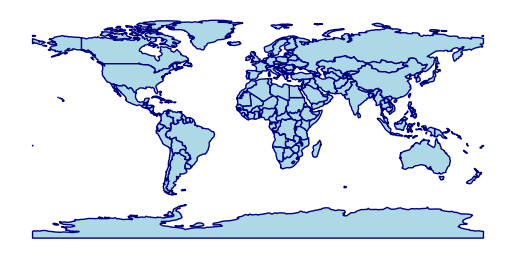

In [3]:
# 2A. Plot the world map
### BEGIN SOLUTION REPLACE ...
ax = world.plot(color="lightblue", edgecolor="navy")
ax.set_axis_off()
### END SOLUTION

<Axes: >

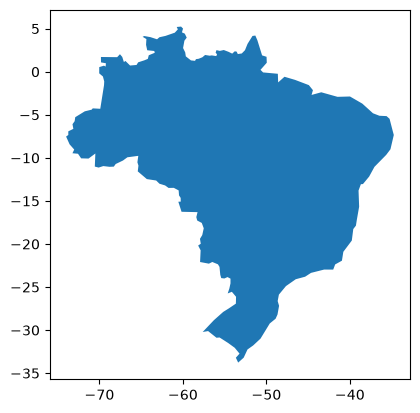

In [4]:
# 2B. Filter and plot Brazil
### BEGIN SOLUTION REPLACE ...
brazil = world.query("ADMIN == 'Brazil'")
brazil.plot()
### END SOLUTION

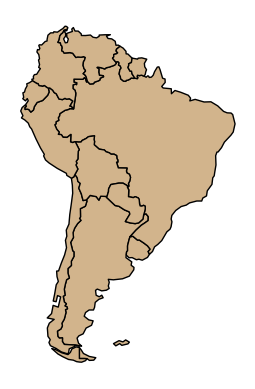

In [5]:
# 2C. Filter and plot South America
### BEGIN SOLUTION REPLACE ...
south_america = world[world["CONTINENT"] == "South America"]
ax = south_america.plot(color="tan", edgecolor="black")
ax.set_axis_off()
### END SOLUTION

In [6]:
# 2D. Compare the two filters
### BEGIN SOLUTION REPLACE ...
by_admin = world.query("ADMIN == 'Denmark'")
by_sov = world.query("SOVEREIGNT == 'Denmark'")
print("ADMIN == Denmark:", by_admin.shape[0])
print("SOVEREIGNT == Denmark:", by_sov.shape[0])
display(by_sov[["ADMIN", "SOVEREIGNT"]])
# SOVEREIGNT groups territories under the country that governs them
# (e.g., Greenland is its own ADMIN entry but Denmark is its sovereign).
### END SOLUTION

ADMIN == Denmark: 1
SOVEREIGNT == Denmark: 2


,ADMIN,SOVEREIGNT
22,Greenland,Denmark
142,Denmark,Denmark


## Exercise 3. Coordinate reference systems and projections

A coordinate reference system (CRS) describes how geographic locations are represented. A projection transforms the curved surface of the Earth onto a flat map, and every projection distorts something.

We will compare:
- `EPSG:4326`: longitude/latitude in degrees (the CRS of the world data)
- `EPSG:3857`: Web Mercator, used by many web maps; strongly inflates areas near the poles
- `ESRI:54009`: Mollweide, an equal-area projection
- `ESRI:54030`: Robinson, a compromise that is neither equal-area nor conformal

Antarctica becomes extremely stretched in Web Mercator, so we remove it first.

**Your tasks**
1. Create `no_ant`, the world data without Antarctica.
2. Plot `no_ant` in its original CRS, then in Web Mercator, Mollweide, and Robinson (use `figsize=(12, 6)` and turn the axes off).
3. Compute the area of Greenland and of Brazil in square kilometres in **Web Mercator** and in **Mollweide**. (Areas are in square metres in these projections; divide by `1e6`.) Compute the ratio Greenland / Brazil in each projection. The true ratio is about 0.25.
4. In a sentence or two, explain which projection you would use for comparing the sizes of countries, and why.

EPSG:4326


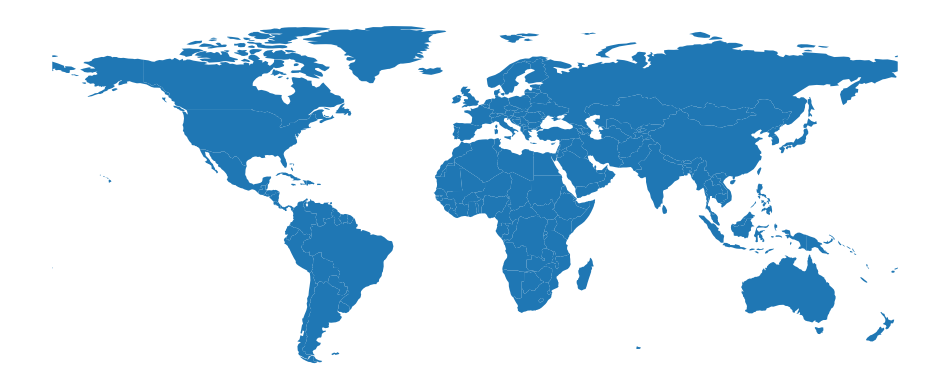

In [7]:
# 3A. Remove Antarctica and plot the original CRS
### BEGIN SOLUTION REPLACE ...
no_ant = world.query("ADMIN != 'Antarctica'")
print(no_ant.crs)
ax = no_ant.plot(figsize=(12, 6))
ax.set_axis_off()
### END SOLUTION

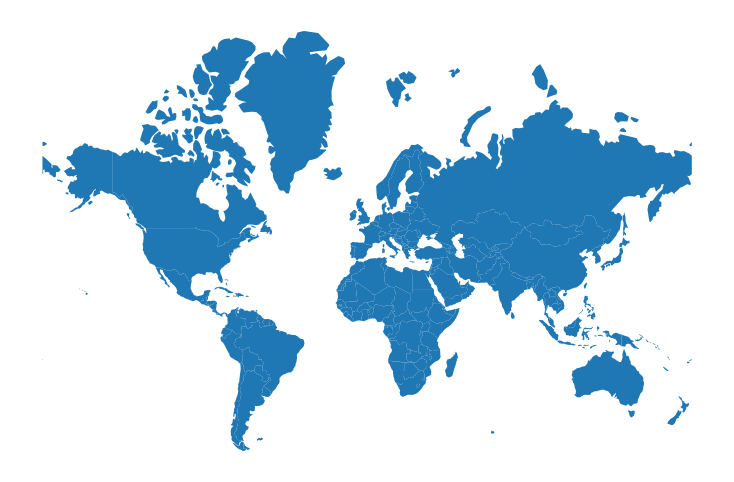

In [8]:
# 3B. Web Mercator
### BEGIN SOLUTION REPLACE ...
ax = no_ant.to_crs("EPSG:3857").plot(figsize=(12, 6))
ax.set_axis_off()
### END SOLUTION

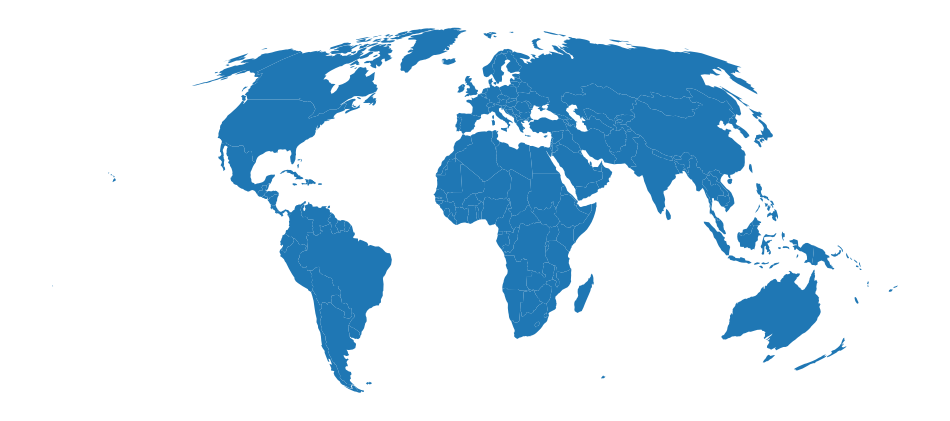

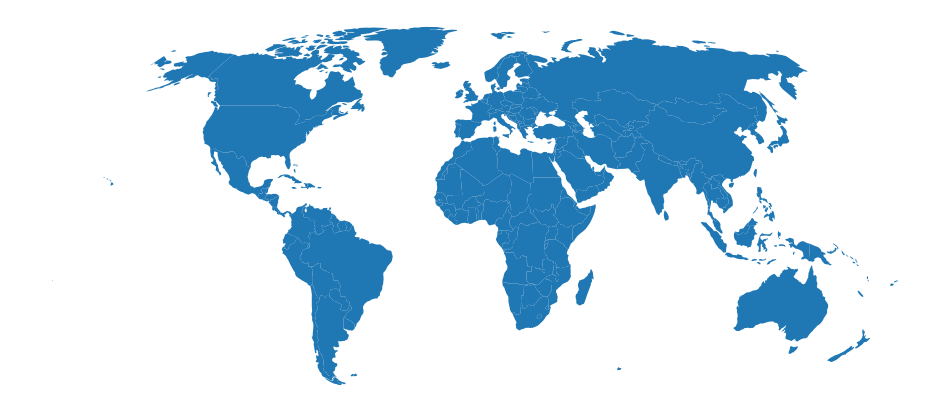

In [9]:
# 3C. Mollweide and Robinson
### BEGIN SOLUTION REPLACE ...
ax = no_ant.to_crs("ESRI:54009").plot(figsize=(12, 6))
ax.set_axis_off()

ax = no_ant.to_crs("ESRI:54030").plot(figsize=(12, 6))
ax.set_axis_off()
### END SOLUTION

In [10]:
# 3D. Compare areas in two projections
### BEGIN SOLUTION REPLACE ...
merc = no_ant.to_crs("EPSG:3857")
moll = no_ant.to_crs("ESRI:54009")

def area_km2(gdf, name):
    return gdf.loc[gdf["ADMIN"] == name].area.iloc[0] / 1e6

for label, gdf in [("Web Mercator", merc), ("Mollweide", moll)]:
    g = area_km2(gdf, "Greenland")
    b = area_km2(gdf, "Brazil")
    print(f"{label}: Greenland = {g:,.0f} km2, Brazil = {b:,.0f} km2, ratio = {g / b:.2f}")
# Mollweide is equal-area, so its ratio is close to the true value of about 0.25.
# Web Mercator inflates areas far from the equator, so Greenland looks much larger.
### END SOLUTION

Web Mercator: Greenland = 36,285,503 km2, Brazil = 9,059,541 km2, ratio = 4.01
Mollweide: Greenland = 2,194,714 km2, Brazil = 8,559,708 km2, ratio = 0.26


**Check your understanding:** Why does it matter that a point layer and a boundary layer use the same CRS? What would you expect to see if you plotted points in degrees on top of a map measured in metres?

## Exercise 4. Add world cities to a map

We will plot the world's major cities on top of the world map. Natural Earth provides a table of populated places.

**Your tasks**
1. Read the populated-places file (code provided) and keep only the columns `NAME`, `ADM0NAME`, `LATITUDE`, `LONGITUDE`, `POP_MAX`, and `ADM0CAP` in a plain DataFrame named `cities`. (Drop the `geometry` column so that we can rebuild it ourselves.)
2. Use `gpd.points_from_xy()` to turn longitude and latitude into point geometries.
3. Make a GeoDataFrame named `cities_gpd`.
4. Check its CRS. Set the CRS to `4326`.
5. Plot `no_ant` in light gray with white edges, then overlay the cities in dark red.
6. Make the marker size proportional to population by passing `markersize=cities_gpd["POP_MAX"] / 500000`.
7. Overlay the national capitals (rows where `ADM0CAP == 1`) in a different color on a second map.

In [11]:
# 4A. Load the cities
places_url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_populated_places.zip"
places = gpd.read_file(places_url)

### BEGIN SOLUTION REPLACE ...
cities = pd.DataFrame(
    places[["NAME", "ADM0NAME", "LATITUDE", "LONGITUDE", "POP_MAX", "ADM0CAP"]]
)
display(cities.head(3))
### END SOLUTION

,NAME,ADM0NAME,LATITUDE,LONGITUDE,POP_MAX,ADM0CAP
0,Vatican City,Vatican,41.903282,12.453387,832,1
1,San Marino,San Marino,43.936096,12.441770,29579,1
2,Vaduz,Liechtenstein,47.133724,9.516670,36281,1


In [12]:
# 4B. Convert longitude and latitude to point geometries
### BEGIN SOLUTION REPLACE ...
city_geometries = gpd.points_from_xy(cities["LONGITUDE"], cities["LATITUDE"])
city_geometries[:5]
### END SOLUTION

<GeometryArray>
[<POINT (12.453 41.903)>, <POINT (12.442 43.936)>,  <POINT (9.517 47.134)>,
  <POINT (31.2 -26.467)>,   <POINT (6.13 49.612)>]
Length: 5, dtype: geometry

In [13]:
# 4C. Create the GeoDataFrame and inspect its CRS
### BEGIN SOLUTION REPLACE ...
cities_gpd = gpd.GeoDataFrame(cities, geometry=city_geometries)
print(cities_gpd.crs)   # None: the points have coordinates but no declared CRS
### END SOLUTION

None


In [14]:
# 4D. Set the CRS
### BEGIN SOLUTION REPLACE ...
cities_gpd = cities_gpd.set_crs(4326)
print(cities_gpd.crs)
### END SOLUTION

EPSG:4326


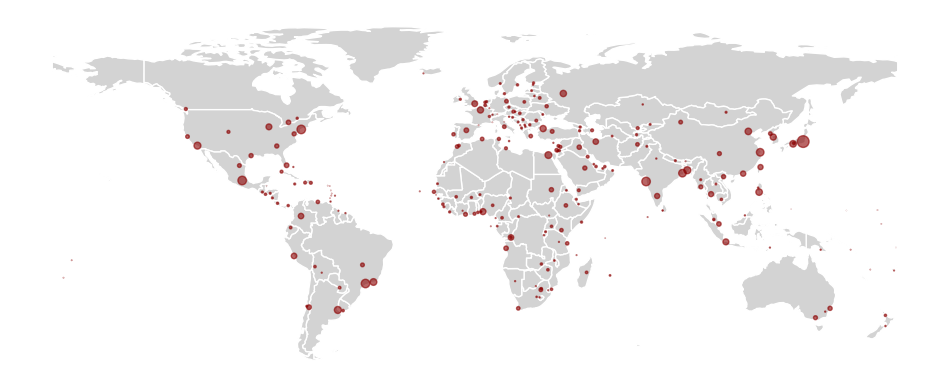

In [15]:
# 4E. Overlay the cities, with marker size proportional to population
### BEGIN SOLUTION REPLACE ...
base = no_ant.plot(color="lightgray", edgecolor="white", figsize=(12, 6))
ax = cities_gpd.plot(
    ax=base, color="darkred", alpha=0.6,
    markersize=cities_gpd["POP_MAX"] / 500000
)
ax.set_axis_off()
### END SOLUTION

199 capitals


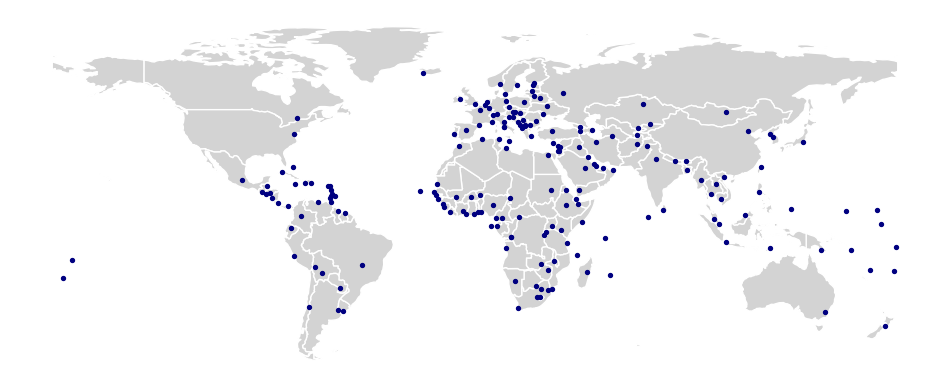

In [16]:
# 4F. Highlight the national capitals
### BEGIN SOLUTION REPLACE ...
capitals = cities_gpd[cities_gpd["ADM0CAP"] == 1]
base = no_ant.plot(color="lightgray", edgecolor="white", figsize=(12, 6))
ax = capitals.plot(ax=base, color="navy", markersize=8)
ax.set_axis_off()
print(capitals.shape[0], "capitals")
### END SOLUTION

**Check your understanding:** In `gpd.points_from_xy(cities["LONGITUDE"], cities["LATITUDE"])`, what would happen if you accidentally reversed the two arguments? Then try this: re-project the world to Robinson with `no_ant.to_crs("ESRI:54030")` and plot the cities on top of it **without** re-projecting them. What goes wrong, and how do you fix it with `to_crs`?

## Exercise 5. Choropleth maps of economic and health data

A choropleth map fills each country according to a numeric value. The `world` GeoDataFrame has country names in `ADMIN`; the Gapminder table has country names in `country`.

**Your tasks**
1. Load the full Gapminder data with `px.data.gapminder()` and create `gapminder_2007`, containing only the rows for 2007.
2. Join `gapminder_2007` to `world` by country name, creating `world_gdp`.
3. Plot `gdpPercap` with the `viridis` color map and a legend. Why is the map hard to read?
4. Try `scheme="quantiles"`. How does this change the map?
5. Compute each country's **gain in life expectancy between 1952 and 2007** (a pandas `pivot_table` is one way). Join it to `world` as `world_gain` and plot it with the `plasma` color map. Which regions improved the most?

In [17]:
# 5A. Load Gapminder
### BEGIN SOLUTION REPLACE ...
gapminder = px.data.gapminder()
gapminder_2007 = gapminder.query("year == 2007")
display(gapminder_2007.head(3))
### END SOLUTION

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12


In [18]:
# 5B. Join the data onto the world map
### BEGIN SOLUTION REPLACE ...
world_gdp = world.merge(gapminder_2007, left_on="ADMIN", right_on="country")
display(world_gdp.head(3))
### END SOLUTION

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_UA,geometry,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,NaN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",Canada,Americas,2007,80.653,33390141,36319.235010,CAN,124
1,Admin-0 country,1,2,Indonesia,IDN,0,2,Sovereign country,1,Indonesia,...,NaN,"MULTIPOLYGON (((141.00021 -2.60015, 141.01706 ...",Indonesia,Asia,2007,70.650,223547000,3540.651564,IDN,360
2,Admin-0 country,1,2,Argentina,ARG,0,2,Sovereign country,1,Argentina,...,NaN,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5...",Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


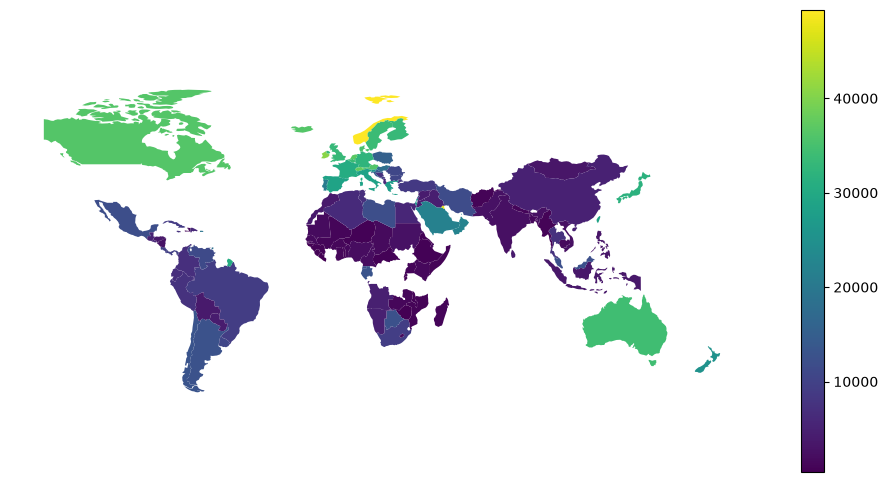

In [19]:
# 5C. Plot GDP per capita
### BEGIN SOLUTION REPLACE ...
ax = world_gdp.plot(column="gdpPercap", cmap="viridis", legend=True, figsize=(12, 6))
ax.set_axis_off()
# A few very rich countries dominate the color scale, so most countries look alike.
### END SOLUTION

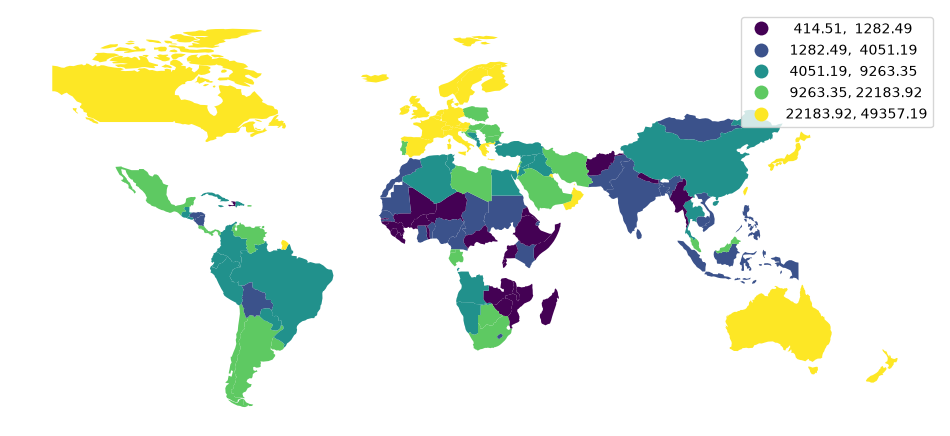

In [20]:
# 5D. Plot GDP per capita using quantiles
### BEGIN SOLUTION REPLACE ...
ax = world_gdp.plot(
    column="gdpPercap", cmap="viridis", scheme="quantiles", legend=True, figsize=(12, 6)
)
ax.set_axis_off()
# Quantile bins put roughly equal numbers of countries in each color class,
# which reveals differences among the many lower-income countries.
### END SOLUTION

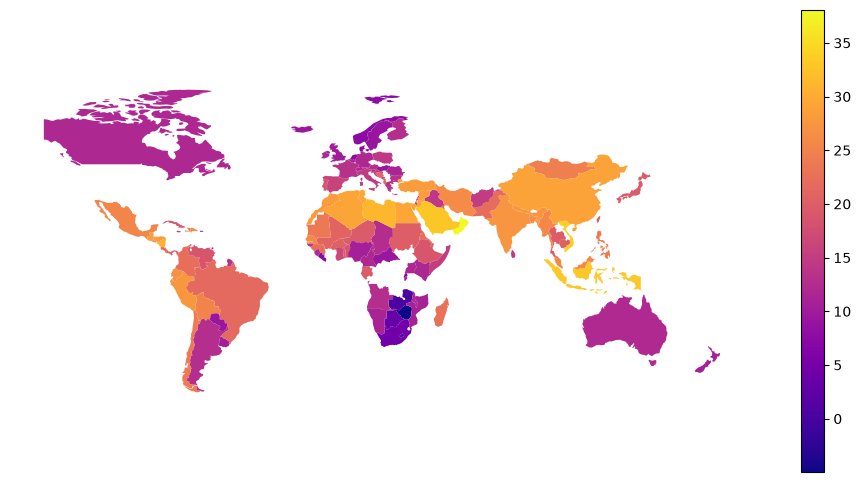

In [21]:
# 5E. Gain in life expectancy, 1952 to 2007
### BEGIN SOLUTION REPLACE ...
life = gapminder.pivot_table(index="country", columns="year", values="lifeExp")
gain = (life[2007] - life[1952]).rename("lifeExp_gain").reset_index()

world_gain = world.merge(gain, left_on="ADMIN", right_on="country")
ax = world_gain.plot(column="lifeExp_gain", cmap="plasma", legend=True, figsize=(12, 6))
ax.set_axis_off()
### END SOLUTION

## Exercise 6. A district-level choropleth: counts or percentages?

Now work at a smaller scale: the 2013 Montreal mayoral election. `px.data.election()` gives vote counts for three candidates in each of 58 districts, and `px.data.election_geojson()` gives the district boundaries as GeoJSON.

**Your tasks**
1. Load both datasets. Turn the GeoJSON into a GeoDataFrame named `districts` with `gpd.GeoDataFrame.from_features(geojson["features"], crs="EPSG:4326")`. Inspect the columns of both.
2. Merge the vote table onto the map using the `district` column, creating `montreal`. Confirm that you still have 58 rows.
3. Plot `Coderre` (the number of votes for one candidate) as a choropleth.
4. Create a new column `percent_coderre`, calculated as `100 * Coderre / total`.
5. Plot `percent_coderre` with a legend.
6. Plot the `winner` column as a categorical map (`categorical=True`, `legend=True`).
7. Explain why the percentage map may be more useful than the count map for comparing districts.

In [ ]:
# 7A. Load the election data and district boundaries
### BEGIN SOLUTION REPLACE ...
election = px.data.election()
geojson = px.data.election_geojson()
districts = gpd.GeoDataFrame.from_features(geojson["features"], crs="EPSG:4326")
display(districts.head(3), election.head(3))
### END SOLUTION

In [ ]:
# 7B. Merge
### BEGIN SOLUTION REPLACE ...
montreal = districts.merge(election, on="district")
print(montreal.shape[0], "districts")
### END SOLUTION

In [ ]:
# 7C. Map the count of votes for Coderre
### BEGIN SOLUTION REPLACE ...
ax = montreal.plot(column="Coderre", cmap="viridis", legend=True)
ax.set_axis_off()
### END SOLUTION

In [ ]:
# 7D. Calculate and map the percentage
### BEGIN SOLUTION REPLACE ...
montreal["percent_coderre"] = 100 * montreal["Coderre"] / montreal["total"]
ax = montreal.plot(column="percent_coderre", cmap="viridis", legend=True)
ax.set_axis_off()
### END SOLUTION

In [ ]:
# 7E. Map the winner in each district
### BEGIN SOLUTION REPLACE ...
ax = montreal.plot(column="winner", categorical=True, legend=True)
ax.set_axis_off()
### END SOLUTION

**Check your understanding:** Compare the count map with the percentage map. Which districts stand out in each? What does each map actually tell you?